# 03 · Classification, final evaluation and Tableau exports

**Executed on real data on 19 October 2026: 19 code cells, 12 inline figures, zero errors or warnings.**

Predict departure delay of at least 15 minutes at a simulated two-hour cutoff for ATL, ORD and DFW. Compare Logistic Regression, KNN, RBF SVM and Random Forest on identical flights:

- A: 10 schedule predictors.
- B: 37 schedule, weather, history and traffic predictors.

| Stage | Period | Sample |
|---|---|---:|
| Initial training | January–September 2025 | 20,000 |
| Validation and selection | October–December 2025 | 5,000 |
| Final refit after decisions freeze | All 12 months of 2025 | 20,000 |
| Final evaluation | January–March 2026 | 10,000 |

This notebook fits new preprocessing inside each pipeline. It writes the validation decision record before loading either the final-refit cohort or test outcomes. Finalized settings and thresholds stay fixed during test evaluation. Scores are not claimed to be calibrated probabilities.

The target is conditional on a noncancelled departure with a known label. Historical schedule, weather receipt and timely outcome-feed availability remain assumptions. Frozen rolling history can use earlier 2026 outcomes only after the declared seven-day lag; the classifier never fits on 2026.

In [1]:
from pathlib import Path
import site
if site.ENABLE_USER_SITE:
    site.addsitedir(site.getusersitepackages())
from datetime import datetime, timezone
from time import perf_counter
from importlib.metadata import version
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (accuracy_score, average_precision_score, precision_score,
    recall_score, f1_score, roc_auc_score, confusion_matrix, precision_recall_curve)

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if (ROOT / 'departure-delay-classification/config/project.json').is_file():
    ROOT = ROOT / 'departure-delay-classification'
CONFIG = json.loads((ROOT / 'config/project.json').read_text())
PREP = json.loads((ROOT / 'reports/preparation_manifest.json').read_text())['feature_engineering']
CONTRACT = json.loads((ROOT / 'tableau/export_contract.json').read_text())
SEED = CONFIG['sampling']['seed']
RUN_ID = datetime.now(timezone.utc).strftime('departure_%Y%m%dT%H%M%S%fZ')
FEATURE_PATH = ROOT / PREP['output']
SELECTION_PATH = ROOT / 'reports/model_selection.json'
OUT = ROOT / CONFIG['tableau']['export_directory']
MODEL_PATH = ROOT / 'models/flight_delay_models.joblib'
FEATURE_SETS = PREP['feature_sets']
CATEGORICAL = ['airline', 'origin', 'destination', 'weekday']
MODEL_NAMES = {'logistic_regression':'Logistic Regression', 'knn':'KNN',
               'svm':'RBF SVM', 'random_forest':'Random Forest'}
PACKAGES = {p: version(p) for p in ['pandas','numpy','scikit-learn','pyarrow',
                                    'matplotlib','seaborn','joblib']}
sns.set_theme(style='whitegrid', palette=['#247BA0','#E08D3C'])
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_columns', 25)

def show_table(data, **kwargs):
    print(data.to_string(**kwargs))

def show_plot():
    plt.tight_layout()
    plt.show()

def file_sha256(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

def json_text(data):
    return json.dumps(data, indent=2, allow_nan=False) + '\n'

def fingerprint(frame):
    ordered = frame[['flight_id','delayed_departure']].sort_values('flight_id')
    payload = '\n'.join(f'{fid}|{int(y)}' for fid, y in ordered.itertuples(index=False, name=None))
    return hashlib.sha256(payload.encode()).hexdigest()

assert file_sha256(FEATURE_PATH) == PREP['output_sha256'], 'Rebuild stale features first.'
assert CONFIG['split'] == PREP['split_definition']
assert CONFIG['preprocessing'] == PREP['preprocessing']
assert [r['feature'] for r in CONFIG['feature_dictionary']] == FEATURE_SETS['B']
assert set(FEATURE_SETS['A']).issubset(FEATURE_SETS['B'])
print('Run:', RUN_ID)
show_table(pd.Series(PACKAGES, name='installed_version').to_frame())

Run: departure_20261018T201555701606Z
             installed_version
pandas                   3.0.3
numpy                    2.5.1
scikit-learn             1.9.0
pyarrow                 20.0.0
matplotlib              3.11.1
seaborn                 0.13.2
joblib                   1.5.3


## 1. Read initial training and validation only

Use the existing model_sample flag; do not resample flights or balance the evaluation classes. The final-refit and test cohorts are loaded in their later sections. Source identities and all outcome/audit fields stay outside the feature allowlists.

In [2]:
def load_cohort(split=None, flag='model_sample'):
    filters = [(flag, '==', True)]
    if split is not None:
        filters.append(('split', '==', split))
    frame = pd.read_parquet(FEATURE_PATH, filters=filters, engine='pyarrow')
    frame = frame.sort_values('flight_id').reset_index(drop=True)
    assert frame['flight_id'].is_unique
    assert frame['delayed_departure'].isin([0,1]).all()
    return frame

train = load_cohort('train')
validation = load_cohort('validation')
for split, frame in [('train',train),('validation',validation)]:
    assert len(frame) == CONFIG['sampling'][split + '_rows']
    assert frame['flight_date'].between(CONFIG['split'][split+'_start'], CONFIG['split'][split+'_end']).all()
assert set(train['flight_id']).isdisjoint(validation['flight_id'])
FORBIDDEN = {'flight_id','delayed_departure','departure_delay_minutes','cancelled','diverted',
             'Tail_Number','source_file','model_sample','refit_sample','month'}
assert not FORBIDDEN.intersection(FEATURE_SETS['B'])
show_table(pd.DataFrame([{'role':name,'rows':len(f),'first_date':str(f['flight_date'].min().date()),
    'last_date':str(f['flight_date'].max().date()),'delayed_fraction':f['delayed_departure'].mean()}
    for name,f in [('initial training',train),('validation',validation)]]),index=False)

            role  rows first_date  last_date  delayed_fraction
initial training 20000 2025-01-01 2025-09-30            0.2584
      validation  5000 2025-10-01 2025-12-31            0.2532


## 2. Declare preprocessing, candidates and selection rules

Numerical medians, optional missingness indicators, category encoding and scaling are fitted inside each candidate's training pipeline. Keep the selective-indicator correction from notebook 02. Scale numerical inputs for LR/KNN/SVM; Random Forest uses the same inputs without scaling.

Search 3 LR settings, 6 KNN settings, 3 RBF-SVM settings and 5 RF settings for each feature set: 34 trials altogether. RF includes its planned starting setting plus four depth/leaf combinations. The winner within each model/feature pair maximizes validation average precision (AP). Exact ties keep the first predeclared setting. The overall validation winner maximizes AP, then uses the fixed model order and A-before-B for ties.

For each finalized pair, choose the validation threshold with the highest delayed-class F1. If F1 ties, use the highest threshold. These rules are fixed before fitting.

In [3]:
def make_preprocessor(feature_set, scale_numeric=True):
    numeric = [c for c in FEATURE_SETS[feature_set] if c not in CATEGORICAL]
    covered = CONFIG['preprocessing']['explicit_missingness_covered_columns']
    transformers = []
    for name, columns, indicators in [
        ('numeric',[c for c in numeric if c not in covered],True),
        ('explicit_flags',[c for c in numeric if c in covered],False)]:
        if columns:
            steps = [('imputer',SimpleImputer(strategy='median',add_indicator=indicators,
                                             keep_empty_features=True))]
            if scale_numeric:
                steps.append(('scaler',StandardScaler()))
            transformers.append((name,Pipeline(steps),columns))
    categories = Pipeline([
        ('imputer',SimpleImputer(strategy='constant',fill_value='Unknown',keep_empty_features=True)),
        ('encoder',OneHotEncoder(handle_unknown='ignore',sparse_output=True,dtype=np.float64))])
    transformers.append(('categorical',categories,CATEGORICAL))
    return ColumnTransformer(transformers,remainder='drop',sparse_threshold=1.0)

ESTIMATORS = {
    'logistic_regression':LogisticRegression(max_iter=3000,random_state=SEED),
    'knn':KNeighborsClassifier(algorithm='brute',n_jobs=2),
    'svm':SVC(kernel='rbf',gamma='scale',cache_size=512,random_state=SEED),
    'random_forest':RandomForestClassifier(**CONFIG['model_options']['random_forest']['initial_parameters'])}
SEARCH = {
    'logistic_regression':list(ParameterGrid({'C':[.1,1.,10.]})),
    'knn':list(ParameterGrid({'n_neighbors':[5,15,31],'weights':['uniform','distance']})),
    'svm':list(ParameterGrid({'C':[.1,1.,10.]})),
    'random_forest':[{'max_depth':12,'min_samples_leaf':10}] +
        list(ParameterGrid(CONFIG['model_options']['random_forest']['small_validation_search']))}
PLAN = {'feature_sets':FEATURE_SETS,'preprocessing':CONFIG['preprocessing'],
    'split':CONFIG['split'],'sampling':CONFIG['sampling'],'search':SEARCH,
    'estimator_defaults':{name:model.get_params() for name,model in ESTIMATORS.items()},
    'selection':'maximum validation AP; fixed model order then A/B breaks ties',
    'threshold':'maximum validation delayed-class F1; highest threshold breaks ties',
    'baseline':'always_on_time; historical airline-origin rate with origin then fit-period prevalence fallback',
    'capacities':CONFIG['evaluation']['capacity_fractions'],
    'subgroup_support':{k:v for k,v in CONFIG['evaluation'].items() if k.startswith('minimum_')}}
PROTOCOL_SHA = hashlib.sha256(json_text(PLAN).encode()).hexdigest()
previous_export = json.loads((OUT/'export_manifest.json').read_text()) if (OUT/'export_manifest.json').exists() else {}
if previous_export:
    assert previous_export['protocol_sha256'] == PROTOCOL_SHA, 'Test already evaluated under another protocol; discuss a new design before changing settings.'
    assert previous_export['feature_input_sha256'] == PREP['output_sha256'], 'Test already evaluated on another feature snapshot.'
print('Declared trials:',sum(map(len,SEARCH.values())) * len(FEATURE_SETS))
show_table(pd.DataFrame([{'model':MODEL_NAMES[m],'settings_per_set':len(s),'settings':json.dumps(s)}
                         for m,s in SEARCH.items()]),index=False)

Declared trials: 34
              model  settings_per_set                                                                                                                                                                                                                                                            settings
Logistic Regression                 3                                                                                                                                                                                                                               [{"C": 0.1}, {"C": 1.0}, {"C": 10.0}]
                KNN                 6 [{"n_neighbors": 5, "weights": "uniform"}, {"n_neighbors": 5, "weights": "distance"}, {"n_neighbors": 15, "weights": "uniform"}, {"n_neighbors": 15, "weights": "distance"}, {"n_neighbors": 31, "weights": "uniform"}, {"n_neighbors": 31, "weights": "distance"}]
            RBF SVM                 3                                                 

## 3. Common scoring helpers and baselines

Precision means how many warnings are actual delays; recall means how many actual delays are found. AP summarizes precision–recall ranking; F1 describes a chosen warning threshold. Accuracy alone can reward predicting the frequent on-time class.

SVM uses its decision score. The other models use their positive-class probability output, labelled uncalibrated. Undefined rates remain missing. Historical risk is a simple comparison using the existing cutoff-respecting history, not a fifth fitted ML algorithm. Random ranking is represented by analytical expected recall/precision.

In [4]:
def model_scores(pipeline, frame, feature_set):
    X = frame[FEATURE_SETS[feature_set]]
    if isinstance(pipeline.named_steps['classifier'],SVC):
        values, kind = pipeline.decision_function(X), 'decision_function'
    else:
        classes = pipeline.named_steps['classifier'].classes_
        values = pipeline.predict_proba(X)[:,list(classes).index(1)]
        kind = 'uncalibrated_probability'
    assert np.isfinite(values).all()
    return np.asarray(values), kind

def threshold_curve(y, scores):
    p,r,t = precision_recall_curve(y,scores)
    f = np.divide(2*p[:-1]*r[:-1],p[:-1]+r[:-1],
                  out=np.zeros(len(t)),where=(p[:-1]+r[:-1])>0)
    return pd.DataFrame({'threshold':t,'precision':p[:-1],'recall':r[:-1],'f1':f})

def best_threshold(y, scores):
    curve = threshold_curve(y,scores)
    tied = np.flatnonzero(np.isclose(curve['f1'],curve['f1'].max(),rtol=0,atol=1e-12))
    return float(curve.iloc[tied[-1]]['threshold'])

def metrics(y, scores, threshold):
    predicted = (np.asarray(scores) >= threshold).astype('int8')
    tn,fp,fn,tp = confusion_matrix(y,predicted,labels=[0,1]).ravel()
    return {'n_flights':len(y),'actual_positive':int(tp+fn),'predicted_positive':int(tp+fp),
        'tp':int(tp),'fp':int(fp),'fn':int(fn),'tn':int(tn),'prevalence':float(np.mean(y)),
        'precision':float(precision_score(y,predicted,zero_division=np.nan)),
        'recall':float(recall_score(y,predicted,zero_division=np.nan)),
        'f1':float(f1_score(y,predicted,zero_division=np.nan)),
        'average_precision':float(average_precision_score(y,scores)) if np.sum(y)>0 else np.nan,
        'roc_auc':float(roc_auc_score(y,scores)) if len(np.unique(y))==2 else np.nan,
        'accuracy':float(accuracy_score(y,predicted))}

def historical_scores(frame, fallback):
    return frame['history_airline_origin_rate'].fillna(frame['history_origin_rate']).fillna(fallback).to_numpy()

dummy = DummyClassifier(strategy='constant',constant=0)
dummy.fit(train[['month_sin']],train['delayed_departure'])
baseline_validation = {}
for model_id in ['always_on_time','historical_risk_ranking']:
    started = perf_counter()
    scores = (dummy.predict_proba(validation[['month_sin']])[:,list(dummy.classes_).index(1)]
              if model_id=='always_on_time' else historical_scores(validation,float(train['delayed_departure'].mean())))
    seconds = perf_counter()-started
    threshold = 1.0 if model_id=='always_on_time' else best_threshold(validation['delayed_departure'],scores)
    baseline_validation[model_id] = {'scores':scores,'threshold':threshold,'prediction_seconds':seconds}
show_table(pd.DataFrame([{'baseline':name,**metrics(validation['delayed_departure'],v['scores'],v['threshold'])}
                         for name,v in baseline_validation.items()]).set_index('baseline'))

                         n_flights  actual_positive  predicted_positive   tp    fp    fn    tn  prevalence  precision   recall        f1  average_precision   roc_auc  accuracy
baseline                                                                                                                                                                       
always_on_time                5000             1266                   0    0     0  1266  3734      0.2532        NaN  0.00000  0.000000           0.253200  0.500000    0.7468
historical_risk_ranking       5000             1266                2990  901  2089   365  1645      0.2532   0.301338  0.71169  0.423402           0.316012  0.593651    0.5092


## 4. Train Logistic Regression on A and B

Every trial fits a fresh pipeline on the same 20,000 initial-training flights and scores the same 5,000 validation flights. Keep the best AP setting for each model/feature pair. A convergence failure stops the notebook rather than silently selecting an unfinished fit.

In [5]:
trials, best = [], {}

def tune_model(model_id):
    for feature_set in ['A','B']:
        key, chosen = (model_id,feature_set), None
        for trial_number, params in enumerate(SEARCH[model_id],start=1):
            print(f'{MODEL_NAMES[model_id]} / {feature_set}: trial {trial_number}/{len(SEARCH[model_id])} {params}',flush=True)
            pipeline = Pipeline([
                ('preprocess',make_preprocessor(feature_set,scale_numeric=model_id!='random_forest')),
                ('classifier',clone(ESTIMATORS[model_id]).set_params(**params))])
            started = perf_counter()
            pipeline.fit(train[FEATURE_SETS[feature_set]],train['delayed_departure'])
            fit_seconds = perf_counter()-started
            classifier = pipeline.named_steps['classifier']
            if isinstance(classifier,LogisticRegression):
                assert classifier.n_iter_.max() < classifier.max_iter, 'LR needs more iterations before selection.'
            if isinstance(classifier,SVC):
                assert classifier.fit_status_==0, 'SVM did not converge.'
            started = perf_counter()
            scores,score_type = model_scores(pipeline,validation,feature_set)
            prediction_seconds = perf_counter()-started
            ap = float(average_precision_score(validation['delayed_departure'],scores))
            row = {'model_id':model_id,'feature_set':feature_set,'trial_number':trial_number,
                   'params':params,'validation_ap':ap,'fit_seconds':fit_seconds,
                   'prediction_seconds':prediction_seconds}
            trials.append(row)
            if chosen is None or ap > chosen['validation_ap']+1e-12:
                chosen = dict(row,pipeline=pipeline,scores=scores,score_type=score_type)
            print(f'  validation AP={ap:.4f}; fit={fit_seconds:.2f}s; score={prediction_seconds:.2f}s',flush=True)
        chosen['threshold'] = best_threshold(validation['delayed_departure'],chosen['scores'])
        best[key] = chosen
        print(f'Kept {MODEL_NAMES[model_id]} / {feature_set}: {chosen["params"]}; threshold={chosen["threshold"]:.6g}',flush=True)

tune_model('logistic_regression')

Logistic Regression / A: trial 1/3 {'C': 0.1}


  validation AP=0.3598; fit=0.04s; score=0.01s


Logistic Regression / A: trial 2/3 {'C': 1.0}


  validation AP=0.3516; fit=0.05s; score=0.00s


Logistic Regression / A: trial 3/3 {'C': 10.0}


...

Logistic Regression / B: trial 2/3 {'C': 1.0}


  validation AP=0.4196; fit=0.14s; score=0.01s


Logistic Regression / B: trial 3/3 {'C': 10.0}


  validation AP=0.4148; fit=0.17s; score=0.01s


Kept Logistic Regression / B: {'C': 0.1}; threshold=0.190701


## 5. Train KNN

Compare k=5/15/31 and uniform/distance weighting. Neighbour distances use the fitted scaled representation.

In [6]:
tune_model('knn')

KNN / A: trial 1/6 {'n_neighbors': 5, 'weights': 'uniform'}


  validation AP=0.2907; fit=0.02s; score=1.22s


KNN / A: trial 2/6 {'n_neighbors': 5, 'weights': 'distance'}


  validation AP=0.2965; fit=0.02s; score=0.95s


KNN / A: trial 3/6 {'n_neighbors': 15, 'weights': 'uniform'}


...

KNN / B: trial 5/6 {'n_neighbors': 31, 'weights': 'uniform'}


  validation AP=0.3621; fit=0.05s; score=1.89s


KNN / B: trial 6/6 {'n_neighbors': 31, 'weights': 'distance'}


  validation AP=0.3730; fit=0.05s; score=1.87s


Kept KNN / B: {'n_neighbors': 31, 'weights': 'distance'}; threshold=0.188576


## 6. Train RBF SVM

Compare C=0.1/1/10 with gamma=scale. Use decision scores directly; no probability-calibration fit is added.

Compatibility note: scikit-learn 1.9 deprecates the explicit probability argument, including False. The constructor omits it and keeps the default decision-score behaviour. No calibration stage is fitted. [SVC documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html).

In [7]:
tune_model('svm')

RBF SVM / A: trial 1/3 {'C': 0.1}


  validation AP=0.2631; fit=5.58s; score=0.92s


RBF SVM / A: trial 2/3 {'C': 1.0}


  validation AP=0.2534; fit=5.96s; score=0.93s


RBF SVM / A: trial 3/3 {'C': 10.0}


...

RBF SVM / B: trial 2/3 {'C': 1.0}


  validation AP=0.3668; fit=9.48s; score=1.66s


RBF SVM / B: trial 3/3 {'C': 10.0}


  validation AP=0.3408; fit=14.55s; score=1.73s


Kept RBF SVM / B: {'C': 1.0}; threshold=-1.04712


## 7. Train Random Forest

Compare the declared five settings using 200 trees, balanced class weights and two workers. The numerical inputs are unscaled.

In [8]:
tune_model('random_forest')

Random Forest / A: trial 1/5 {'max_depth': 12, 'min_samples_leaf': 10}


  validation AP=0.3737; fit=0.67s; score=0.03s


Random Forest / A: trial 2/5 {'max_depth': 8, 'min_samples_leaf': 5}


  validation AP=0.3705; fit=0.54s; score=0.03s


Random Forest / A: trial 3/5 {'max_depth': 8, 'min_samples_leaf': 20}


...

Random Forest / B: trial 4/5 {'max_depth': 16, 'min_samples_leaf': 5}


  validation AP=0.4157; fit=1.97s; score=0.05s


Random Forest / B: trial 5/5 {'max_depth': 16, 'min_samples_leaf': 20}


  validation AP=0.4125; fit=1.37s; score=0.03s


Kept Random Forest / B: {'max_depth': 16, 'min_samples_leaf': 5}; threshold=0.407835


## 8. Compare validation evidence and inspect fitting behaviour

Compare tuned A/B AP and F1, parameter sensitivity, runtimes and training-versus-validation AP. Training scores are resubstitution diagnostics, especially optimistic for KNN because training neighbours can include the same flight. They are not generalization estimates.

Pick the overall winner using validation AP only. A/B contrasts measure the combined additional feature package; these runs cannot isolate separate weather, history and traffic benefits.

Validation-selected candidate: Logistic Regression / feature set B
           model_id feature_set                                     params  training_ap  average_precision  precision   recall       f1  threshold  fit_seconds  prediction_seconds
logistic_regression           A                                 {"C": 0.1}     0.423448           0.359801   0.336394 0.636651 0.440197   0.189194     0.040256            0.005273
logistic_regression           B                                 {"C": 0.1}     0.464673           0.425474   0.362985 0.680095 0.473337   0.190701     0.091525            0.008512
                knn           A {"n_neighbors": 31, "weights": "distance"}     0.998811           0.336122   0.294169 0.793049 0.429152   0.155624     0.021975            0.902076
                knn           B {"n_neighbors": 31, "weights": "distance"}     1.000000           0.373026   0.326778 0.682464 0.441944   0.188576     0.051693            1.867835
                svm           A  

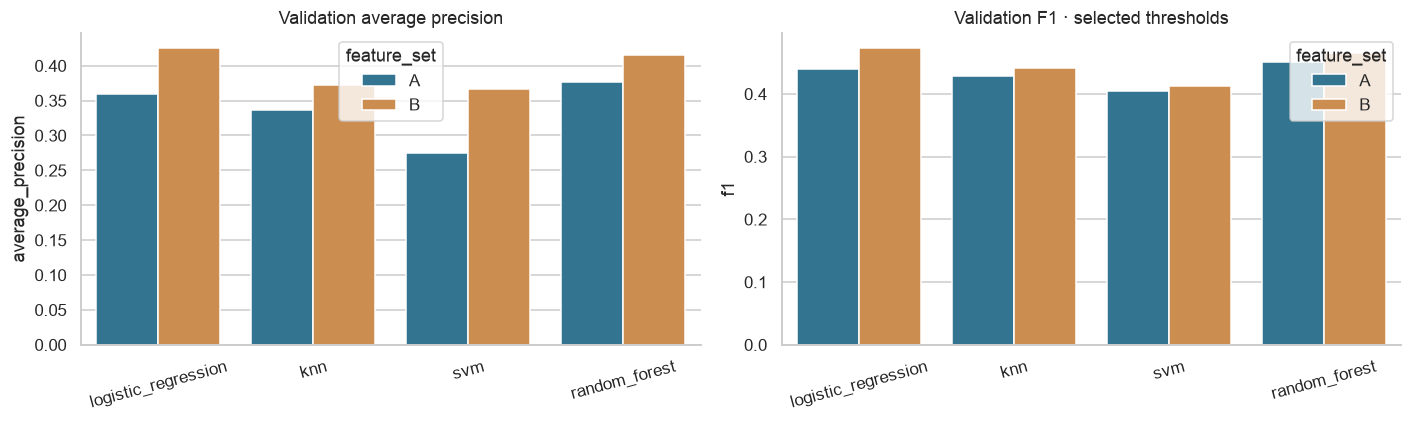

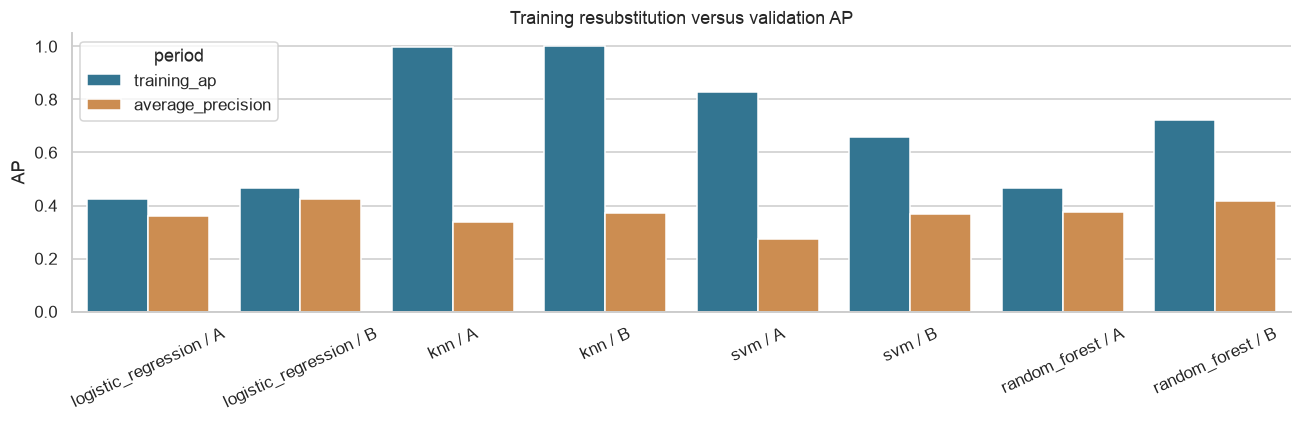

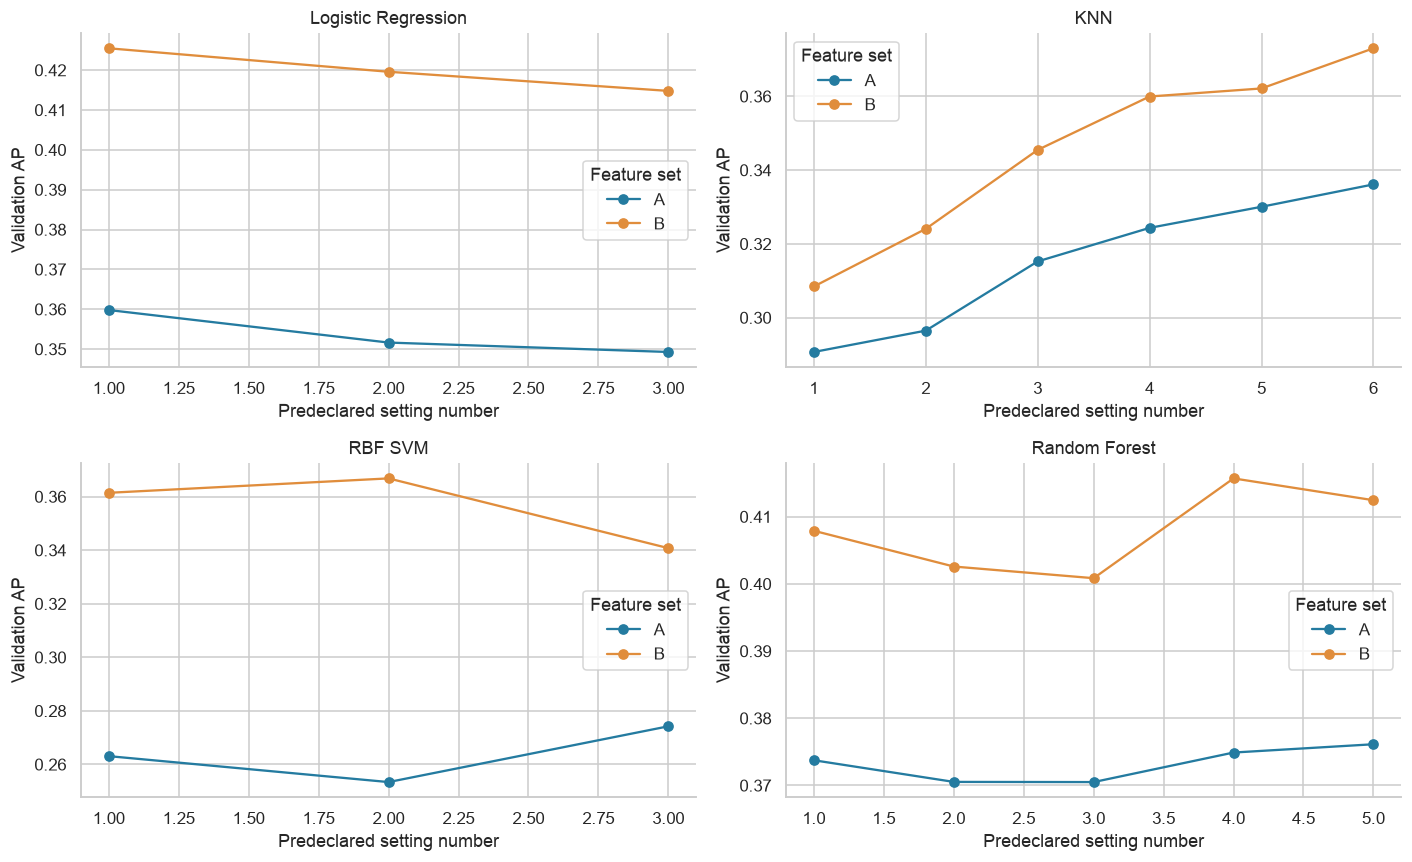

           model_id feature_set  trial_number                                     params  validation_ap
logistic_regression           A             1                                 {'C': 0.1}       0.359801
logistic_regression           A             2                                 {'C': 1.0}       0.351640
logistic_regression           A             3                                {'C': 10.0}       0.349279
logistic_regression           B             1                                 {'C': 0.1}       0.425474
logistic_regression           B             2                                 {'C': 1.0}       0.419585
logistic_regression           B             3                                {'C': 10.0}       0.414785
                knn           A             1   {'n_neighbors': 5, 'weights': 'uniform'}       0.290691
                knn           A             2  {'n_neighbors': 5, 'weights': 'distance'}       0.296479
                knn           A             3  {'n_neighbors': 1

In [9]:
validation_rows = []
for (model_id,feature_set), item in best.items():
    train_scores,_ = model_scores(item['pipeline'],train,feature_set)
    validation_rows.append({'model_id':model_id,'feature_set':feature_set,'params':json.dumps(item['params']),
        'threshold':item['threshold'],'fit_seconds':item['fit_seconds'],
        'prediction_seconds':item['prediction_seconds'],
        'training_ap':float(average_precision_score(train['delayed_departure'],train_scores)),
        **metrics(validation['delayed_departure'],item['scores'],item['threshold'])})
validation_summary = pd.DataFrame(validation_rows)
order = {name:i for i,name in enumerate(MODEL_NAMES)}
ranked = validation_summary.assign(_order=validation_summary['model_id'].map(order)).sort_values(
    ['average_precision','_order','feature_set'],ascending=[False,True,True],kind='stable')
SELECTED = (ranked.iloc[0]['model_id'],ranked.iloc[0]['feature_set'])
print('Validation-selected candidate:',MODEL_NAMES[SELECTED[0]],'/ feature set',SELECTED[1])
show_table(validation_summary[['model_id','feature_set','params','training_ap','average_precision',
    'precision','recall','f1','threshold','fit_seconds','prediction_seconds']],index=False)
fig,axes = plt.subplots(1,2,figsize=(13,4))
for metric,ax,title in [('average_precision',axes[0],'Validation average precision'),
                        ('f1',axes[1],'Validation F1 · selected thresholds')]:
    sns.barplot(data=validation_summary,x='model_id',y=metric,hue='feature_set',errorbar=None,ax=ax)
    ax.set(title=title,xlabel='',ylabel=metric);ax.tick_params(axis='x',rotation=15)
show_plot()

diagnostic = validation_summary.assign(candidate=lambda f:f['model_id']+' / '+f['feature_set']).melt(
    id_vars='candidate',value_vars=['training_ap','average_precision'],var_name='period',value_name='AP')
fig,ax=plt.subplots(figsize=(12,4))
sns.barplot(data=diagnostic,x='candidate',y='AP',hue='period',errorbar=None,ax=ax)
ax.set(title='Training resubstitution versus validation AP',xlabel='');ax.tick_params(axis='x',rotation=25)
show_plot()

trial_table = pd.DataFrame(trials)
fig,axes=plt.subplots(2,2,figsize=(13,8))
for model_id,ax in zip(MODEL_NAMES,axes.flat):
    for feature_set in ['A','B']:
        line=trial_table.loc[trial_table['model_id'].eq(model_id)&trial_table['feature_set'].eq(feature_set)]
        ax.plot(line['trial_number'],line['validation_ap'],marker='o',label=feature_set)
    ax.set(title=MODEL_NAMES[model_id],xlabel='Predeclared setting number',ylabel='Validation AP')
    ax.legend(title='Feature set')
show_plot()
show_table(trial_table[['model_id','feature_set','trial_number','params','validation_ap']],index=False)

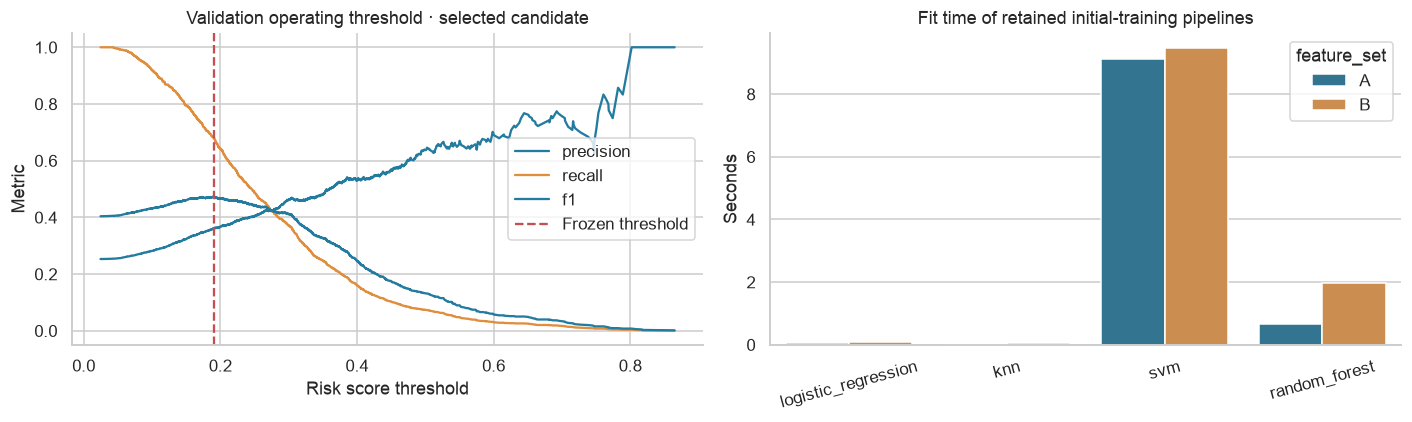

Chosen threshold is optimized on validation, not on 2026 outcomes.


In [10]:
chosen = best[SELECTED]
operating_curve = threshold_curve(validation['delayed_departure'],chosen['scores'])
fig,axes = plt.subplots(1,2,figsize=(13,4))
for metric in ['precision','recall','f1']:
    axes[0].plot(operating_curve['threshold'],operating_curve[metric],label=metric)
axes[0].axvline(chosen['threshold'],color='#C44E52',linestyle='--',label='Frozen threshold')
axes[0].set(title='Validation operating threshold · selected candidate',xlabel='Risk score threshold',ylabel='Metric')
axes[0].legend()
sns.barplot(data=validation_summary,x='model_id',y='fit_seconds',hue='feature_set',errorbar=None,ax=axes[1])
axes[1].set(title='Fit time of retained initial-training pipelines',xlabel='',ylabel='Seconds')
axes[1].tick_params(axis='x',rotation=15)
show_plot()
print('Chosen threshold is optimized on validation, not on 2026 outcomes.')

## 9. Freeze the selection record before any final-refit/test loading

Save all eight selected configurations, their validation thresholds and scores, the overall winner, the complete search ledger, protocol/source fingerprints and environment versions. No test outcome has been loaded by this notebook yet.

The same predeclared threshold is retained after refit; a changed score distribution can therefore affect test F1. AP separately evaluates ranking. A completed run can be reproduced with the same protocol, while a changed protocol after test exposure stops for discussion.

In [11]:
FROZEN_AT = datetime.now(timezone.utc).isoformat()
selection = {'run_id':RUN_ID,'frozen_at_utc':FROZEN_AT,'protocol_sha256':PROTOCOL_SHA,'protocol':PLAN,
    'feature_input_sha256':PREP['output_sha256'],'training_cohort_fingerprint':fingerprint(train),
    'validation_cohort_fingerprint':fingerprint(validation),'selected_model_id':SELECTED[0],
    'selected_feature_set':SELECTED[1],'packages':PACKAGES,'trial_results':trials,
    'choices':[{'model_id':m,'feature_set':f,'params':v['params'],'threshold':v['threshold'],
                'score_type':v['score_type'],'validation_ap':v['validation_ap']}
               for (m,f),v in best.items()],
    'baselines':{name:{'threshold':v['threshold']} for name,v in baseline_validation.items()},
    'test_loaded_during_selection':False,'class_weighting':'RF balanced; other model defaults',
    'historical_simulation_note':CONFIG['evaluation']['availability_disclosure']}
SELECTION_PATH.write_text(json_text(selection))
SELECTION_SHA = file_sha256(SELECTION_PATH)
print('Saved:',SELECTION_PATH.relative_to(ROOT))
print('Selection frozen at:',FROZEN_AT)
print('Selection checksum:',SELECTION_SHA)

Saved: reports/model_selection.json
Selection frozen at: 2026-10-18T20:17:49.804348+00:00
Selection checksum: e7bf8c43a20c3dddaed1b9935e80a8fba406cf7179edac1ca89cfb27a081c18f


## 10. Refit the finalized pipelines on the full-2025 sample

Now load the independent refit_sample: 20,000 flights proportionally covering January–December 2025. It can overlap initial-training/validation samples and excludes every 2026 flight. Fit fresh medians, encoders, scalers and estimators using the frozen settings. No further parameter or threshold search occurs.

In [12]:
assert file_sha256(SELECTION_PATH)==SELECTION_SHA
refit = load_cohort(flag='refit_sample')
assert len(refit)==CONFIG['sampling']['refit_rows']
assert refit['flight_date'].between(CONFIG['split']['refit_start'],CONFIG['split']['refit_end']).all()
assert set(refit['month'])==set(range(1,13))
final_models, final_fit_seconds = {}, {}
for key,item in best.items():
    print('Final refit:',MODEL_NAMES[key[0]],'/',key[1],flush=True)
    pipeline = clone(item['pipeline'])
    started = perf_counter()
    pipeline.fit(refit[FEATURE_SETS[key[1]]],refit['delayed_departure'])
    final_fit_seconds[key]=perf_counter()-started
    clf=pipeline.named_steps['classifier']
    if isinstance(clf,LogisticRegression):
        assert clf.n_iter_.max()<clf.max_iter
    if isinstance(clf,SVC):
        assert clf.fit_status_==0
    final_models[key]=pipeline
dummy_final=clone(dummy).fit(refit[['month_sin']],refit['delayed_departure'])
print('All eight final pipelines fitted on 2025 only.')

Final refit: Logistic Regression / A


Final refit: Logistic Regression / B


Final refit: KNN / A


Final refit: KNN / B


Final refit: RBF SVM / A


Final refit: RBF SVM / B


Final refit: Random Forest / A


Final refit: Random Forest / B


All eight final pipelines fitted on 2025 only.


## 11. Load the reserved 2026 test once and score frozen models

The first test outcome access in this notebook is below. Run all eight already-finalized comparisons; retain the validation-selected winner even if another candidate has a larger test metric.

Validation predictions come from the initial-training pipelines. Test predictions come from the full-2025 refits. Label their different fitting periods when interpreting changes.

In [13]:
assert file_sha256(SELECTION_PATH)==SELECTION_SHA
TEST_LOADED_AT=datetime.now(timezone.utc).isoformat()
test=load_cohort('test')
assert len(test)==CONFIG['sampling']['test_rows']
assert test['flight_date'].between(CONFIG['split']['test_start'],CONFIG['split']['test_end']).all()
assert set(test['flight_id']).isdisjoint(set(train['flight_id'])|set(validation['flight_id'])|set(refit['flight_id']))
assert pd.Timestamp(TEST_LOADED_AT)>pd.Timestamp(FROZEN_AT)
evaluations=[]
for key,item in best.items():
    model_id,feature_set=key
    evaluations.append({'split':'validation','model_id':model_id,'feature_set':feature_set,
        'frame':validation,'scores':item['scores'],'score_type':item['score_type'],
        'threshold':item['threshold'],'fit_seconds':item['fit_seconds'],
        'prediction_seconds':item['prediction_seconds']})
    started=perf_counter()
    scores,score_type=model_scores(final_models[key],test,feature_set)
    seconds=perf_counter()-started
    evaluations.append({'split':'test','model_id':model_id,'feature_set':feature_set,'frame':test,
        'scores':scores,'score_type':score_type,'threshold':item['threshold'],
        'fit_seconds':final_fit_seconds[key],'prediction_seconds':seconds})
    print(f'Test scored: {MODEL_NAMES[model_id]} / {feature_set} ({seconds:.2f}s)',flush=True)
for name,item in baseline_validation.items():
    evaluations.append({'split':'validation','model_id':name,'feature_set':'baseline','frame':validation,
        'scores':item['scores'],'score_type':'baseline_score','threshold':item['threshold'],
        'fit_seconds':0.,'prediction_seconds':item['prediction_seconds']})
    started=perf_counter()
    scores=(dummy_final.predict_proba(test[['month_sin']])[:,list(dummy_final.classes_).index(1)]
        if name=='always_on_time' else historical_scores(test,float(refit['delayed_departure'].mean())))
    evaluations.append({'split':'test','model_id':name,'feature_set':'baseline','frame':test,'scores':scores,
        'score_type':'baseline_score','threshold':item['threshold'],'fit_seconds':0.,
        'prediction_seconds':perf_counter()-started})
print('Completed frozen test scoring; settings and thresholds remain unchanged.')

Test scored: Logistic Regression / A (0.01s)


Test scored: Logistic Regression / B (0.02s)


Test scored: KNN / A (2.71s)


Test scored: KNN / B (4.15s)


Test scored: RBF SVM / A (1.95s)


Test scored: RBF SVM / B (3.41s)


Test scored: Random Forest / A (0.05s)


Test scored: Random Forest / B (0.08s)


Completed frozen test scoring; settings and thresholds remain unchanged.


## 12. Build auditable prediction, metric and curve tables

One prediction row represents one flight for one model/feature pair and evaluation split. Ties are broken by a seed/flight hash independent of the outcome. Classification errors use the frozen threshold; top-quota review metrics use ranks and are a different operating scenario.

Precision–recall curve endpoints can lack a threshold. Keep those values missing. Record raw subgroup counts even when support rules suppress unreliable rates.

In [14]:
prediction_parts,metric_rows,curve_parts,priority_rows,subgroup_rows=[],[],[],[],[]
for e in evaluations:
    frame=e['frame']; y=frame['delayed_departure'].to_numpy()
    selected=(e['model_id'],e['feature_set'])==SELECTED
    cohort_id=f'{RUN_ID}_{e["split"]}_{len(frame)}'
    cohort_sha=fingerprint(frame)
    shared={'run_id':RUN_ID,'model_id':e['model_id'],'feature_set':e['feature_set'],
            'split':e['split'],'cohort_id':cohort_id}
    result=metrics(y,e['scores'],e['threshold'])
    metric_rows.append(dict(shared,**result,fit_seconds=e['fit_seconds'],
        prediction_seconds=e['prediction_seconds'],decision_threshold=e['threshold'],
        is_validation_selected=selected,cohort_fingerprint=cohort_sha,
        evaluation_scenario='historical_availability_assumptions'))
    p=frame[['flight_id','flight_date','scheduled_departure_utc','prediction_cutoff_utc',
             'origin','destination','airline','departure_time_band']].rename(columns={'airline':'reporting_airline'}).copy()
    p['flight_date']=p['flight_date'].dt.strftime('%Y-%m-%d')
    for field in ['scheduled_departure_utc','prediction_cutoff_utc']:
        p[field]=p[field].dt.strftime('%Y-%m-%dT%H:%M:%SZ')
    for field,value in {k:v for k,v in shared.items() if k!='cohort_id'}.items():
        p[field]=value
    p['y_true']=y;p['risk_score']=e['scores'];p['score_type']=e['score_type']
    p['decision_threshold']=e['threshold'];p['y_pred']=(p['risk_score']>=e['threshold']).astype('int8')
    p['confusion_label']=np.select([p.y_true.eq(1)&p.y_pred.eq(1),p.y_true.eq(0)&p.y_pred.eq(1),
                                    p.y_true.eq(1)&p.y_pred.eq(0)],['TP','FP','FN'],default='TN')
    p['is_validation_selected']=selected
    p['ranking_tie_key']=[hashlib.sha256(f'{SEED}:{fid}'.encode()).hexdigest() for fid in p['flight_id']]
    p=p.sort_values(['risk_score','ranking_tie_key'],ascending=[False,True],kind='stable').reset_index(drop=True)
    p['rank_cohort_id']=cohort_id;p['risk_rank']=np.arange(1,len(p)+1);p['rank_cohort_size']=len(p)
    prediction_parts.append(p)
    precision,recall,thresholds=precision_recall_curve(y,e['scores'])
    curve=pd.DataFrame({'point_index':np.arange(len(precision)),'threshold':np.r_[thresholds,np.nan],
                        'precision':precision,'recall':recall})
    for field,value in shared.items():
        curve[field]=value
    curve['n_flights']=len(y);curve['actual_positive']=int(np.sum(y));curve_parts.append(curve)
    for capacity in CONFIG['evaluation']['capacity_fractions']:
        k=int(np.ceil(capacity*len(p)));captured=int(p.head(k)['y_true'].sum())
        priority_rows.append(dict(shared,capacity_fraction=capacity,n_flights=len(p),
            actual_positive=int(np.sum(y)),reviewed_flights=k,realized_review_fraction=k/len(p),
            captured_delays=captured,false_alerts=k-captured,capture_recall=captured/np.sum(y),
            review_precision=captured/k,lift_over_prevalence=(captured/k)/np.mean(y),
            random_expected_recall=k/len(p),random_expected_precision=float(np.mean(y)),
            ranking_tie_policy='SHA256(seed:flight_id), ascending within tied scores',
            cohort_fingerprint=cohort_sha))
    for dimension in CONFIG['evaluation']['subgroup_dimensions']:
        for group,block in p.groupby(dimension,observed=True):
            tn,fp,fn,tp=confusion_matrix(block.y_true,block.y_pred,labels=[0,1]).ravel()
            supported=len(block)>=CONFIG['evaluation']['minimum_group_rows']
            pr_ok=supported and tp+fp>=CONFIG['evaluation']['minimum_predicted_positives_for_precision']
            re_ok=supported and tp+fn>=CONFIG['evaluation']['minimum_actual_positives_for_recall']
            fp_ok=supported and tn+fp>=CONFIG['evaluation']['minimum_actual_negatives_for_fpr']
            subgroup_rows.append(dict(shared,group_dimension=dimension,group_value=str(group),
                n_flights=len(block),actual_positive=int(tp+fn),actual_negative=int(tn+fp),
                predicted_positive=int(tp+fp),tp=int(tp),fp=int(fp),fn=int(fn),tn=int(tn),
                precision=tp/(tp+fp) if pr_ok else np.nan,recall=tp/(tp+fn) if re_ok else np.nan,
                false_negative_rate=fn/(tp+fn) if re_ok else np.nan,
                false_positive_rate=fp/(tn+fp) if fp_ok else np.nan,
                precision_supported=bool(pr_ok),recall_supported=bool(re_ok),
                false_positive_rate_supported=bool(fp_ok)))
predictions=pd.concat(prediction_parts,ignore_index=True)
model_metrics=pd.DataFrame(metric_rows)
pr_curves=pd.concat(curve_parts,ignore_index=True)
priority=pd.DataFrame(priority_rows)
subgroups=pd.DataFrame(subgroup_rows)
feature_rows=[]
for split,frame in [('validation',validation),('test',test)]:
    for model_id in MODEL_NAMES:
        pair=model_metrics.loc[model_metrics.split.eq(split)&model_metrics.model_id.eq(model_id)].set_index('feature_set')
        a=predictions.loc[predictions.split.eq(split)&predictions.model_id.eq(model_id)&predictions.feature_set.eq('A')].sort_values('flight_id')
        b=predictions.loc[predictions.split.eq(split)&predictions.model_id.eq(model_id)&predictions.feature_set.eq('B')].sort_values('flight_id')
        identical=a[['flight_id','y_true']].reset_index(drop=True).equals(b[['flight_id','y_true']].reset_index(drop=True))
        assert identical
        feature_rows.append({'run_id':RUN_ID,'model_id':model_id,'split':split,'cohort_id':pair.loc['A','cohort_id'],
            'base_feature_set':'A','added_feature_set':'B','n_common_flights':len(frame),
            'identical_ids_and_labels':identical,'cohort_fingerprint':fingerprint(frame),
            'base_average_precision':pair.loc['A','average_precision'],'added_average_precision':pair.loc['B','average_precision'],
            'delta_average_precision':pair.loc['B','average_precision']-pair.loc['A','average_precision'],
            'base_f1':pair.loc['A','f1'],'added_f1':pair.loc['B','f1'],'delta_f1':pair.loc['B','f1']-pair.loc['A','f1'],
            'added_feature_coverage':float((frame['weather_report_missing'].eq(0)&frame['history_origin_n'].gt(0)).mean()),
            'status':'completed','unavailable_reason':None})
comparisons=pd.DataFrame(feature_rows)
test_metrics=model_metrics.loc[model_metrics.split.eq('test')].copy()
show_table(test_metrics[['model_id','feature_set','average_precision','precision','recall','f1','accuracy','roc_auc',
                         'tp','fp','fn','tn','fit_seconds','prediction_seconds']],index=False)

               model_id feature_set  average_precision  precision   recall       f1  accuracy  roc_auc   tp   fp   fn   tn  fit_seconds  prediction_seconds
    logistic_regression           A           0.361243   0.303639 0.756703 0.433379    0.4982 0.630143 1919 4401  617 3063     0.041666            0.009346
    logistic_regression           B           0.405501   0.327171 0.760647 0.457543    0.5426 0.668435 1929 3967  607 3497     0.095838            0.015626
                    knn           A           0.305148   0.275279 0.815852 0.411659    0.4086 0.578481 2069 5447  467 2017     0.022554            2.705390
                    knn           B           0.358157   0.295201 0.783517 0.428833    0.4707 0.618687 1987 4744  549 2720     0.052826            4.152589
                    svm           A           0.292640   0.253866 0.996845 0.404674    0.2562 0.539588 2528 7430    8   34     9.354631            1.947401
                    svm           B           0.366809   0.28153

## 13. O1 and O2 · Final model performance and A/B value

Use final test results to report performance of the validation-selected choice and all predeclared alternatives. A/B AP differences compare rankings on identical flights. A/B F1 differences also reflect their separately validation-chosen thresholds. The comparison includes tuning within the same small model-specific search, rather than proving one individual added variable caused a gain.

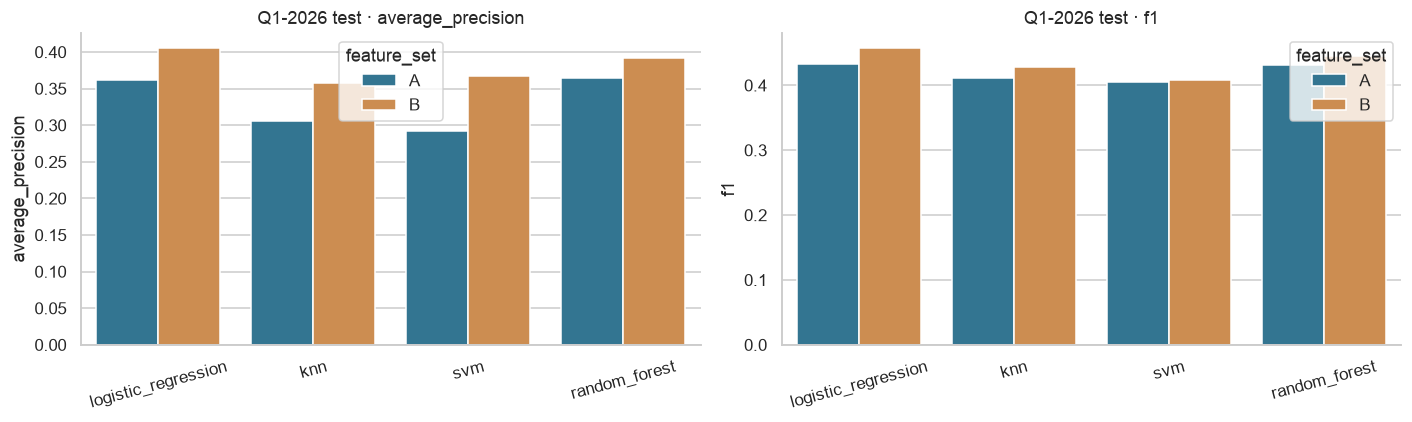

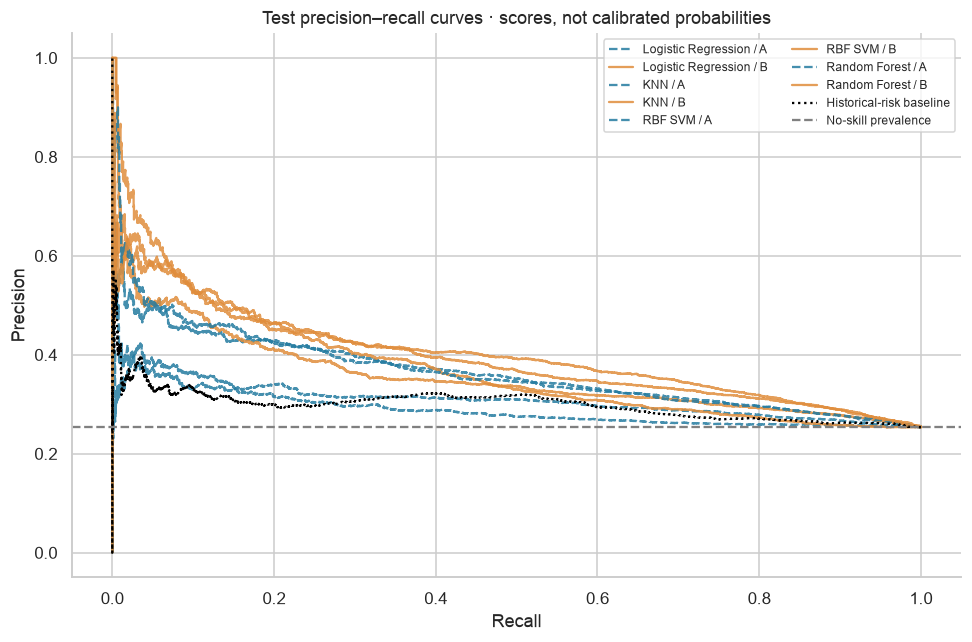

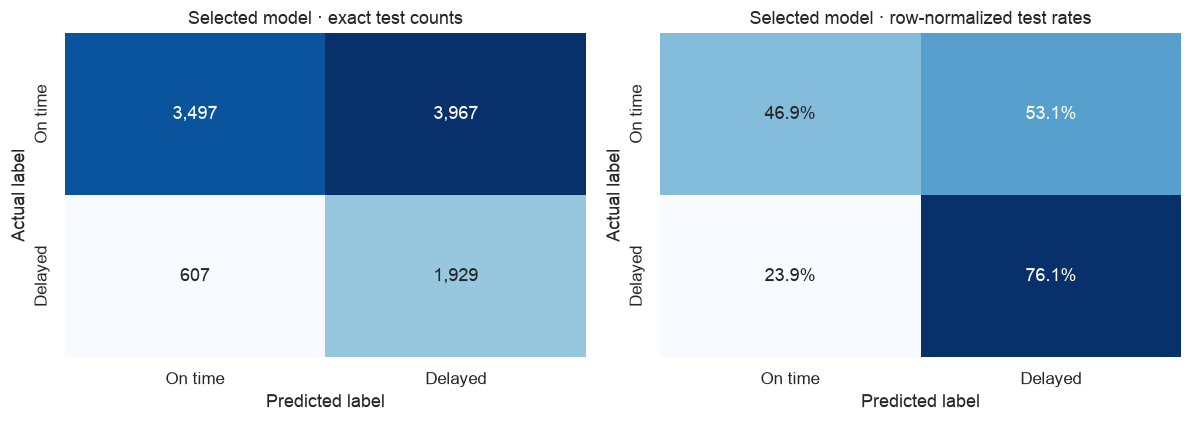

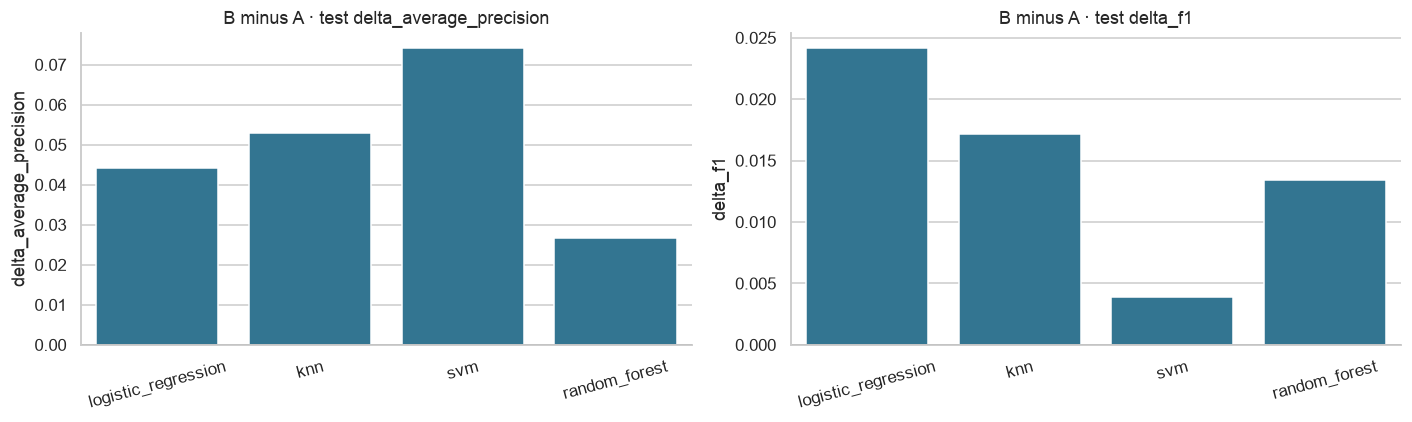

                          run_id            model_id      split                                        cohort_id base_feature_set added_feature_set  n_common_flights  identical_ids_and_labels                                               cohort_fingerprint  base_average_precision  added_average_precision  delta_average_precision  base_f1  added_f1  delta_f1  added_feature_coverage    status unavailable_reason
departure_20261018T201555701606Z logistic_regression validation departure_20261018T201555701606Z_validation_5000                A                 B              5000                      True 063c36cc45b0d54c2aa7589f88b6871d2c5d4eb610ed2883770f47f2d11ed2df                0.359801                 0.425474                 0.065673 0.440197  0.473337  0.033140                     1.0 completed               None
departure_20261018T201555701606Z                 knn validation departure_20261018T201555701606Z_validation_5000                A                 B              5000         

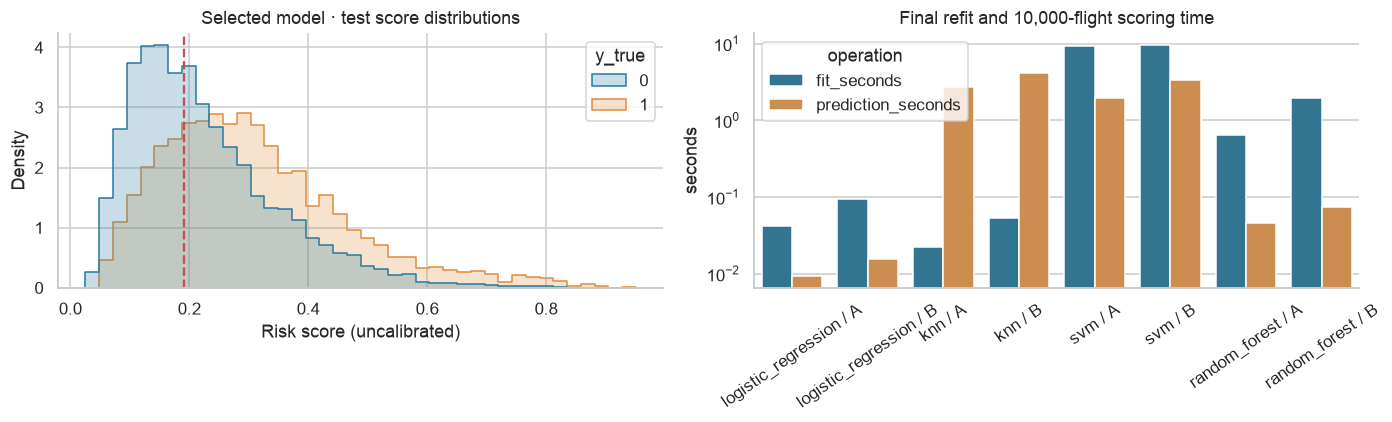

In [15]:
ml_test=test_metrics.loc[test_metrics.model_id.isin(MODEL_NAMES)]
fig,axes=plt.subplots(1,2,figsize=(13,4))
for metric,ax in [('average_precision',axes[0]),('f1',axes[1])]:
    sns.barplot(data=ml_test,x='model_id',y=metric,hue='feature_set',errorbar=None,ax=ax)
    ax.set(title='Q1-2026 test · '+metric,xlabel='');ax.tick_params(axis='x',rotation=15)
show_plot()

fig,ax=plt.subplots(figsize=(9,6))
for (model_id,feature_set),line in pr_curves.loc[pr_curves.split.eq('test')].groupby(['model_id','feature_set'],sort=False):
    if model_id in MODEL_NAMES:
        ax.plot(line['recall'],line['precision'],linestyle='-' if feature_set=='B' else '--',
                label=MODEL_NAMES[model_id]+' / '+feature_set,alpha=.85)
history_line=pr_curves.loc[pr_curves.split.eq('test')&pr_curves.model_id.eq('historical_risk_ranking')]
ax.plot(history_line['recall'],history_line['precision'],color='black',linestyle=':',label='Historical-risk baseline')
ax.axhline(test['delayed_departure'].mean(),color='grey',linestyle='--',label='No-skill prevalence')
ax.set(title='Test precision–recall curves · scores, not calibrated probabilities',xlabel='Recall',ylabel='Precision')
ax.legend(fontsize=8,ncol=2);show_plot()

selected_test=predictions.loc[predictions.split.eq('test')&predictions.is_validation_selected].copy()
assert len(selected_test)==len(test)
matrix=confusion_matrix(selected_test.y_true,selected_test.y_pred,labels=[0,1])
fig,axes=plt.subplots(1,2,figsize=(11,4))
sns.heatmap(matrix,annot=True,fmt=',d',cmap='Blues',cbar=False,ax=axes[0])
sns.heatmap(matrix/matrix.sum(axis=1,keepdims=True),annot=True,fmt='.1%',cmap='Blues',cbar=False,ax=axes[1])
for ax,title in zip(axes,['Selected model · exact test counts','Selected model · row-normalized test rates']):
    ax.set(title=title,xlabel='Predicted label',ylabel='Actual label',xticklabels=['On time','Delayed'],yticklabels=['On time','Delayed'])
show_plot()

fig,axes=plt.subplots(1,2,figsize=(13,4))
for metric,ax in [('delta_average_precision',axes[0]),('delta_f1',axes[1])]:
    sns.barplot(data=comparisons.loc[comparisons.split.eq('test')],x='model_id',y=metric,color='#247BA0',ax=ax)
    ax.axhline(0,color='black',linewidth=1);ax.set(title='B minus A · test '+metric,xlabel='')
    ax.tick_params(axis='x',rotation=15)
show_plot()
show_table(comparisons,index=False)

fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.histplot(data=selected_test,x='risk_score',hue='y_true',bins=40,stat='density',common_norm=False,
             element='step',ax=axes[0])
axes[0].axvline(chosen['threshold'],color='#C44E52',linestyle='--')
axes[0].set(title='Selected model · test score distributions',xlabel='Risk score (uncalibrated)')
runtime=ml_test.melt(id_vars=['model_id','feature_set'],value_vars=['fit_seconds','prediction_seconds'],
                    var_name='operation',value_name='seconds')
runtime['candidate']=runtime['model_id']+' / '+runtime['feature_set']
sns.barplot(data=runtime,x='candidate',y='seconds',hue='operation',errorbar=None,ax=axes[1])
axes[1].set(title='Final refit and 10,000-flight scoring time',xlabel='',yscale='log')
axes[1].tick_params(axis='x',rotation=35)
show_plot()

## 14. O3 · Where the selected model misses delays or raises false warnings

Recall/miss rate uses actual delayed flights as its denominator. False-positive rate uses actual on-time flights. Precision uses predicted warnings. Apply the agreed support rules; missing rates mean insufficient support, not zero errors. Subgroup rates describe this sampled Q1 period, not inherent airline/airport quality.

    group_dimension     group_value  n_flights  tp   fp  fn   tn  precision   recall  false_negative_rate  false_positive_rate  precision_supported  recall_supported  false_positive_rate_supported
             origin             ATL       3250 445 1033 262 1510   0.301083 0.629420             0.370580             0.406213                 True              True                           True
             origin             DFW       3094 651 1136 200 1107   0.364298 0.764982             0.235018             0.506465                 True              True                           True
             origin             ORD       3656 833 1798 145  880   0.316610 0.851738             0.148262             0.671397                 True              True                           True
  reporting_airline              AA       2308 680 1079 102  447   0.386583 0.869565             0.130435             0.707077                 True              True                           True
  reporting_air

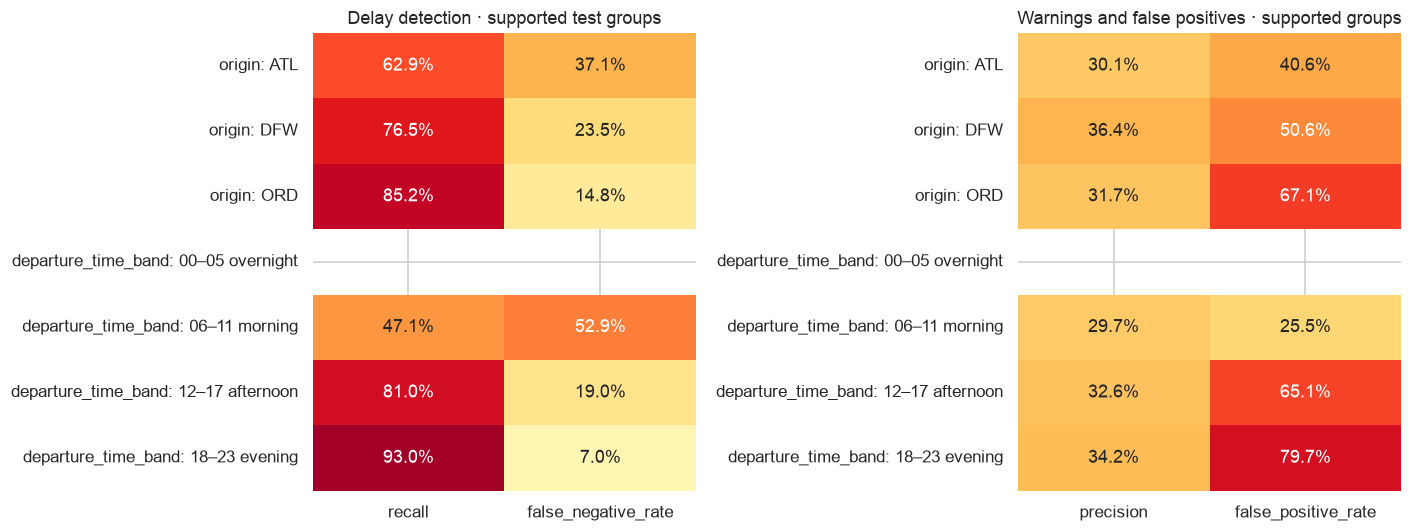

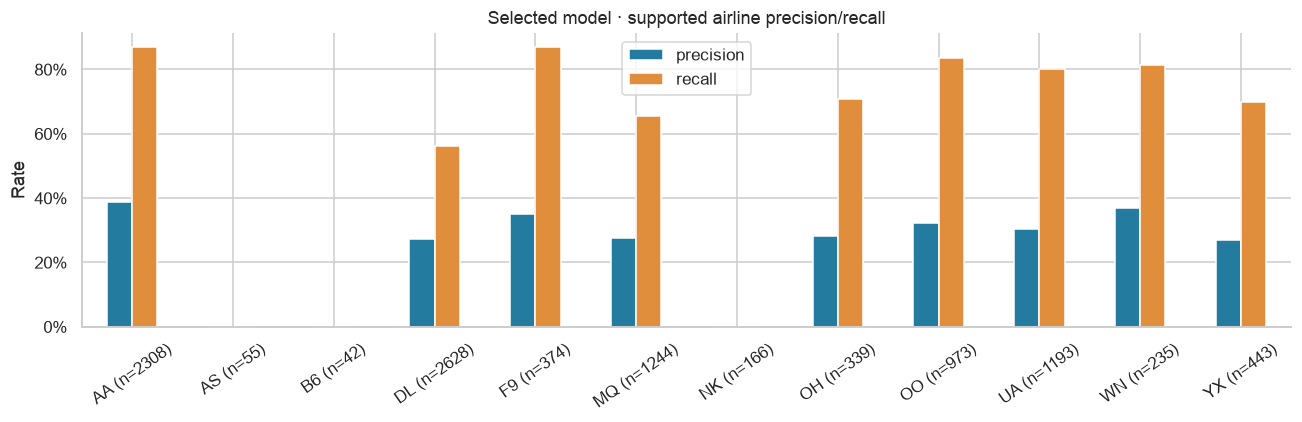

In [16]:
reliability=subgroups.loc[subgroups.split.eq('test')&subgroups.model_id.eq(SELECTED[0])&
                         subgroups.feature_set.eq(SELECTED[1])].copy()
show_table(reliability[['group_dimension','group_value','n_flights','tp','fp','fn','tn',
                       'precision','recall','false_negative_rate','false_positive_rate',
                       'precision_supported','recall_supported','false_positive_rate_supported']],index=False)
local=reliability.loc[reliability.group_dimension.isin(['origin','departure_time_band'])].copy()
local['group']=local['group_dimension']+': '+local['group_value']
fig,axes=plt.subplots(1,2,figsize=(13,5))
for cols,ax,title in [(['recall','false_negative_rate'],axes[0],'Delay detection · supported test groups'),
                     (['precision','false_positive_rate'],axes[1],'Warnings and false positives · supported groups')]:
    values=local.set_index('group')[cols]
    sns.heatmap(values,mask=values.isna(),annot=True,fmt='.1%',cmap='YlOrRd',vmin=0,vmax=1,cbar=False,ax=ax)
    ax.set(title=title,ylabel='')
show_plot()
airlines=reliability.loc[reliability.group_dimension.eq('reporting_airline')].copy()
airlines['airline_with_count']=airlines['group_value']+' (n='+airlines['n_flights'].astype(str)+')'
fig,ax=plt.subplots(figsize=(12,4))
airlines.set_index('airline_with_count')[['precision','recall']].plot.bar(ax=ax)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title='Selected model · supported airline precision/recall',xlabel='',ylabel='Rate')
ax.tick_params(axis='x',rotation=35);show_plot()

## 15. O4 · Can a limited review list concentrate actual delays?

Rank within the fixed test cohort. At K=ceil(capacity × N), report captured delays, recall, precision, false alerts and lift over prevalence. Compare the selected model with historical-risk ranking and random expectation. These quotas are retrospective review scenarios; they do not change the frozen classification threshold or prove delays could have been prevented.

               model_id feature_set  capacity_fraction  reviewed_flights  captured_delays  false_alerts  capture_recall  review_precision  lift_over_prevalence  random_expected_recall  random_expected_precision
    logistic_regression           B               0.05               500              263           237        0.103707            0.5260              2.074132                    0.05                     0.2536
    logistic_regression           B               0.10              1000              471           529        0.185726            0.4710              1.857256                    0.10                     0.2536
    logistic_regression           B               0.20              2000              830          1170        0.327287            0.4150              1.636435                    0.20                     0.2536
historical_risk_ranking    baseline               0.05               500              168           332        0.066246            0.3360              1.324

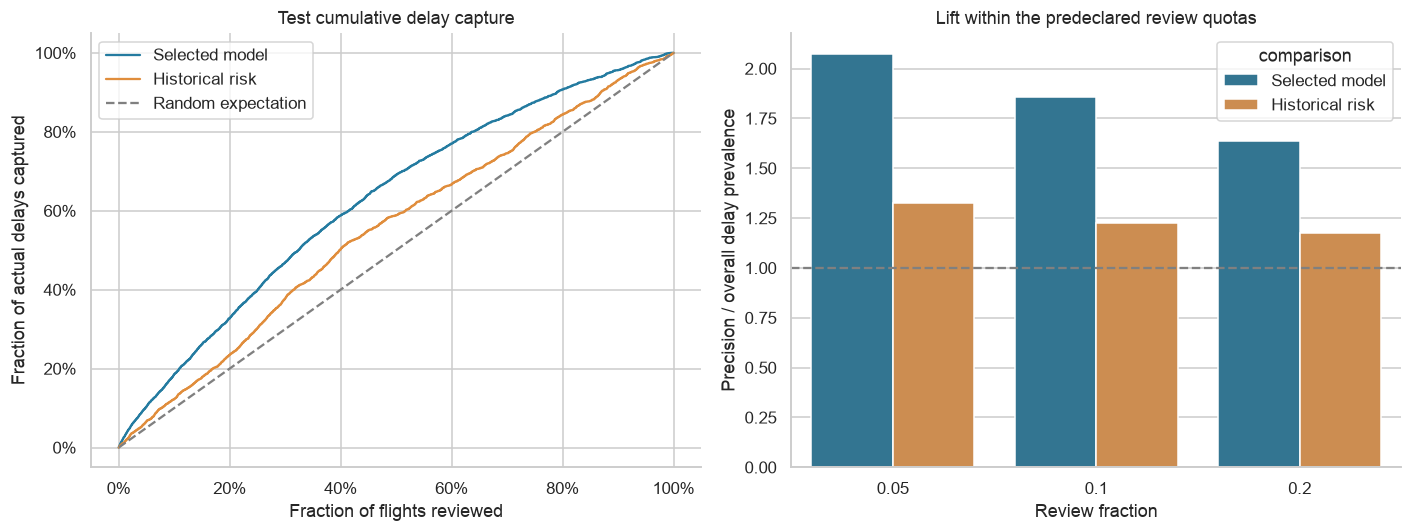

In [17]:
selected_priority=priority.loc[priority.split.eq('test')&
    (((priority.model_id.eq(SELECTED[0]))&priority.feature_set.eq(SELECTED[1]))|
      priority.model_id.eq('historical_risk_ranking'))]
show_table(selected_priority[['model_id','feature_set','capacity_fraction','reviewed_flights',
    'captured_delays','false_alerts','capture_recall','review_precision','lift_over_prevalence',
    'random_expected_recall','random_expected_precision']],index=False)
fig,axes=plt.subplots(1,2,figsize=(13,5))
for name,line in [('Selected model',selected_test),('Historical risk',predictions.loc[
    predictions.split.eq('test')&predictions.model_id.eq('historical_risk_ranking')])]:
    line=line.sort_values('risk_rank')
    axes[0].plot(np.r_[0,line.risk_rank/len(line)],np.r_[0,line.y_true.cumsum()/line.y_true.sum()],label=name)
axes[0].plot([0,1],[0,1],linestyle='--',color='grey',label='Random expectation')
axes[0].set(title='Test cumulative delay capture',xlabel='Fraction of flights reviewed',ylabel='Fraction of actual delays captured')
axes[0].xaxis.set_major_formatter(PercentFormatter(1));axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend()
plot_priority=selected_priority.assign(comparison=lambda f:np.where(f.model_id.eq('historical_risk_ranking'),'Historical risk','Selected model'))
sns.barplot(data=plot_priority,x='capacity_fraction',y='lift_over_prevalence',hue='comparison',errorbar=None,ax=axes[1])
axes[1].axhline(1,color='grey',linestyle='--')
axes[1].set(title='Lift within the predeclared review quotas',xlabel='Review fraction',ylabel='Precision / overall delay prevalence')
show_plot()

## 16. Validate and save the six Tableau tables and fitted pipelines

Check the declared grain, IDs, confusion totals, missing-rate/support rules and quota counts. The feature-coverage figure means a valid weather report and nonempty origin history; it does not imply that every weather field is observed.

Export exactly the six result tables in the existing contract. Save the eight final fitted pipelines in one joblib bundle, together with their thresholds and selection metadata. The input Parquet files and notebooks 01/02/02a are not modified.

In [18]:
tables={'flight_predictions.csv':predictions,'model_metrics.csv':model_metrics,
    'feature_comparison.csv':comparisons,'subgroup_metrics.csv':subgroups,
    'priority_curve.csv':priority,'pr_curve.csv':pr_curves}
for name,table in tables.items():
    spec=CONTRACT['tables'][name]
    assert set(spec['fields']).issubset(table.columns),(name,'missing columns')
    assert not table.duplicated(spec['grain']).any(),(name,'repeated grain')
    assert table['run_id'].eq(RUN_ID).all()
assert (model_metrics[['tp','fp','fn','tn']].sum(axis=1)==model_metrics.n_flights).all()
assert (model_metrics.tp+model_metrics.fn==model_metrics.actual_positive).all()
assert (model_metrics.tp+model_metrics.fp==model_metrics.predicted_positive).all()
assert len(predictions)==10*(len(validation)+len(test))
assert comparisons.identical_ids_and_labels.all()
for e in evaluations:
    block=predictions.loc[predictions.split.eq(e['split'])&predictions.model_id.eq(e['model_id'])&
                          predictions.feature_set.eq(e['feature_set'])]
    assert set(block.flight_id)==set(e['frame'].flight_id)
    assert sorted(block.risk_rank)==list(range(1,len(block)+1))
    assert np.array_equal(block.y_pred.to_numpy(),(block.risk_score>=e['threshold']).astype('int8').to_numpy())
    assert np.allclose(block.risk_score,e['scores'][block.flight_id.map(
        pd.Series(np.arange(len(e['frame'])),index=e['frame'].flight_id)).to_numpy()])
for _,row in priority.iterrows():
    block=predictions.loc[predictions.split.eq(row['split'])&predictions.model_id.eq(row['model_id'])&
                          predictions.feature_set.eq(row['feature_set'])&predictions.risk_rank.le(row['reviewed_flights'])]
    assert len(block)==row['reviewed_flights'] and block.y_true.sum()==row['captured_delays']
assert subgroups.loc[~subgroups.recall_supported,'recall'].isna().all()
assert subgroups.loc[~subgroups.precision_supported,'precision'].isna().all()
assert subgroups.loc[~subgroups.false_positive_rate_supported,'false_positive_rate'].isna().all()
assert file_sha256(SELECTION_PATH)==SELECTION_SHA
assert file_sha256(FEATURE_PATH)==PREP['output_sha256']
stage=OUT/('.staged_'+RUN_ID);stage.mkdir(parents=True,exist_ok=False)
for name,table in tables.items():
    # Native missing values become blank CSV fields, never strings such as "nan".
    table[list(CONTRACT['tables'][name]['fields'])].to_csv(stage/name,index=False,encoding='utf-8',na_rep='')
    saved=pd.read_csv(stage/name)
    assert len(saved)==len(table) and not saved.duplicated(CONTRACT['tables'][name]['grain']).any()
bundle={'run_id':RUN_ID,'selection':selection,'selection_sha256':SELECTION_SHA,
        'models':{m+'__'+f:{'pipeline':pipe,'threshold':best[(m,f)]['threshold'],
                   'score_type':best[(m,f)]['score_type'],'feature_set':f}
                  for (m,f),pipe in final_models.items()},
        'historical_baseline_fallback':float(refit.delayed_departure.mean()),
        'baseline_thresholds':{name:v['threshold'] for name,v in baseline_validation.items()},
        'always_on_time':dummy_final}
MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(bundle,MODEL_PATH,compress=3)
export_files={}
for name in tables:
    (stage/name).replace(OUT/name)
    export_files[name]={'rows':len(tables[name]),'sha256':file_sha256(OUT/name)}
stage.rmdir()
export_manifest={'run_id':RUN_ID,'status':'completed','completed_at_utc':datetime.now(timezone.utc).isoformat(),
    'protocol_sha256':PROTOCOL_SHA,'selection_record':'reports/model_selection.json',
    'selection_sha256':SELECTION_SHA,'frozen_at_utc':FROZEN_AT,'test_first_loaded_this_run_utc':TEST_LOADED_AT,
    'holdout_first_evaluated_at_utc':previous_export.get('holdout_first_evaluated_at_utc',TEST_LOADED_AT),
    'selected_model_id':SELECTED[0],'selected_feature_set':SELECTED[1],
    'feature_input_sha256':PREP['output_sha256'],'source_manifest_sha256':file_sha256(ROOT/'data/SOURCE_MANIFEST.json'),
    'cohorts':{name:{'rows':len(frame),'fingerprint':fingerprint(frame)} for name,frame in
               [('initial_training',train),('validation',validation),('final_refit',refit),('test',test)]},
    'files':export_files,'model_bundle':str(MODEL_PATH.relative_to(ROOT)),
    'model_bundle_sha256':file_sha256(MODEL_PATH),'packages':PACKAGES,
    'fit_periods':{'validation':'2025-01 through 2025-09','test':'2025-01 through 2025-12'},
    'coverage_definition':'Valid cutoff-matched weather report and nonempty origin history; individual fields can remain missing.',
    'selection_rule':'Validation AP; thresholds use validation delayed-class F1; all frozen before test.',
    'study_design':'Historical simulation; weather/outcome receipt and archived schedule availability assumed.',
    'history_policy':'Frozen rolling 28-day window ending seven days before cutoff; earlier 2026 outcomes may enter later histories after the lag.',
    'score_note':'SVM decision scores and uncalibrated model probabilities are risk scores, not verified delay probabilities.',
    'csv_nulls':'empty field; undefined and unsupported rates remain missing','classifiers_trained':True}
(OUT/'export_manifest.json').write_text(json_text(export_manifest))
print('Saved model bundle:',MODEL_PATH.relative_to(ROOT))
show_table(pd.DataFrame([{'table':name,**v} for name,v in export_files.items()]),index=False)
print('All export integrity checks passed. The Tableau workbook itself is the next stage.')

Saved model bundle: models/flight_delay_models.joblib
                 table   rows                                                           sha256
flight_predictions.csv 150000 a52596583a3bf5e0020bed80330ca397263525fd4e34a6f701ced3cb955dac3f
     model_metrics.csv     20 87080d4a6a624b0c989ad65bb00f93297fe5dbfdb78959c94ee3ed293f9ffb92
feature_comparison.csv      8 9506540a3edb2bddce366583f678e4240eca6a317a0852f4cd3ad15465f4b9ea
  subgroup_metrics.csv    380 8a0d143cf5c8d35a7001e8db91d8e16927492b16e0617b226446c090a5bb3274
    priority_curve.csv     60 bb49e4ea336e24dbe668877bb2f92ddb02968c042ddfb4261a089c224f2fd646
          pr_curve.csv 132279 62175280b6db10af4fbb229d18f2eb8518ca01c5aa14516348419b8b562b3d0e
All export integrity checks passed. The Tableau workbook itself is the next stage.


## 17. Record findings against the project objectives

The text below is generated from actual frozen test results. It distinguishes the validation-selected choice from the largest test metric, reports combined A/B changes, supported subgroup behaviour and prioritization usefulness. Modest or negative results are valid findings; no accuracy target was promised.

In [19]:
s=test_metrics.loc[test_metrics.model_id.eq(SELECTED[0])&test_metrics.feature_set.eq(SELECTED[1])].iloc[0]
v=validation_summary.loc[validation_summary.model_id.eq(SELECTED[0])&validation_summary.feature_set.eq(SELECTED[1])].iloc[0]
ten=selected_priority.loc[selected_priority.model_id.eq(SELECTED[0])&selected_priority.capacity_fraction.eq(.1)].iloc[0]
hist_ten=selected_priority.loc[selected_priority.model_id.eq('historical_risk_ranking')&selected_priority.capacity_fraction.eq(.1)].iloc[0]
best_test=ml_test.sort_values('average_precision',ascending=False).iloc[0]
changes=comparisons.loc[comparisons.split.eq('test')]
supported_recall=reliability.loc[reliability.recall_supported]
weak=supported_recall.sort_values('recall').iloc[0]
findings=[
 f'Validation selected {MODEL_NAMES[SELECTED[0]]} / {SELECTED[1]} with AP {v.average_precision:.4f}.',
 f'Frozen test performance: AP {s.average_precision:.4f}, precision {s.precision:.1%}, recall {s.recall:.1%}, F1 {s.f1:.4f}, accuracy {s.accuracy:.1%}, ROC-AUC {s.roc_auc:.4f}.',
 f'On {int(s.n_flights):,} test flights: {int(s.tp):,} correctly warned delays, {int(s.fp):,} false warnings, {int(s.fn):,} missed delays and {int(s.tn):,} correct on-time predictions.',
 f'The largest descriptive test AP is {best_test.average_precision:.4f} for {MODEL_NAMES[best_test.model_id]} / {best_test.feature_set}; the registered validation choice remains unchanged.',
 'A-to-B test AP changes: '+ '; '.join(f'{MODEL_NAMES[r.model_id]} {r.delta_average_precision:+.4f}' for r in changes.itertuples())+'.',
 f'Lowest supported selected-model recall: {weak.group_dimension}={weak.group_value}, {weak.recall:.1%} across {int(weak.n_flights):,} flights. This is descriptive, not an intrinsic quality ranking.',
 f'The top 10% review list captures {int(ten.captured_delays):,} delays ({ten.capture_recall:.1%} of actual delays), with {ten.review_precision:.1%} precision, lift {ten.lift_over_prevalence:.2f} and {int(ten.false_alerts):,} non-delayed reviewed flights.',
 f'The same historical-risk review quota captures {hist_ten.capture_recall:.1%} of delays with {hist_ten.review_precision:.1%} precision; random expected recall is {ten.random_expected_recall:.1%}.',
 'A/B measures the combined additional feature package, not separate causal contributions from weather, history or traffic.',
 'Validation metrics used for selection are optimistic development evidence. Test results cover a proportional sample of Q1 2026 at three hubs; repeated weather reports and airport-days limit independence.',
 'Thresholds are retained after full-2025 refitting, without test recalibration. Score shifts can affect F1 even when ranking AP changes differently.',
 'Historical delivery and schedule availability are assumed, not verified live. The target excludes cancelled flights and aircraft rotation is outside scope.',
 'The six Tableau tables and one fitted-model bundle are saved. Creating and checking the Tableau workbook remains a separate stage.'
]
for text in findings:
    print('- '+text)
report='# Classification results\n\nRun: '+RUN_ID+'\n\n'+'\n\n'.join('- '+text for text in findings)
report+='\n\nSee the executed notebook, reports/model_selection.json and tableau/exports/export_manifest.json for settings, thresholds, cohort fingerprints and source lineage.\n'
(ROOT/'reports/MODELLING_RESULTS.md').write_text(report)
print('\nSaved reports/MODELLING_RESULTS.md')

- Validation selected Logistic Regression / B with AP 0.4255.
- Frozen test performance: AP 0.4055, precision 32.7%, recall 76.1%, F1 0.4575, accuracy 54.3%, ROC-AUC 0.6684.
- On 10,000 test flights: 1,929 correctly warned delays, 3,967 false warnings, 607 missed delays and 3,497 correct on-time predictions.
- The largest descriptive test AP is 0.4055 for Logistic Regression / B; the registered validation choice remains unchanged.
- A-to-B test AP changes: Logistic Regression +0.0443; KNN +0.0530; RBF SVM +0.0742; Random Forest +0.0267.
- Lowest supported selected-model recall: departure_time_band=06–11 morning, 47.1% across 3,552 flights. This is descriptive, not an intrinsic quality ranking.
- The top 10% review list captures 471 delays (18.6% of actual delays), with 47.1% precision, lift 1.86 and 529 non-delayed reviewed flights.
- The same historical-risk review quota captures 12.3% of delays with 31.1% precision; random expected recall is 10.0%.
- A/B measures the combined additio